# 02 · Limpieza y preprocesamiento
**Proyecto integrador — Lector de Facturas** · Sebastián Rojas y Jesús López

El lector no entrena pesos, así que "preparar los datos" tiene dos partes:

1. **Limpieza de las referencias** (etiquetas): qué documentos y campos se pueden usar para medir y cómo se normalizan fechas y montos.
2. **Preprocesamiento de la imagen** antes del OCR. El modelo final («resumen contable») lee cada imagen con **10 vistas**: 5 con los pesos `tessdata_fast` (original, ampliada y Otsu con distintos PSM), 4 con `tessdata_best` (incluida una vista con corrección de iluminación) y 1 en inglés + español con filtro de ruido. Si la lectura es poco confiable o los importes no coinciden entre vistas, añade hasta **2 vistas de rescate** con binarización local.

La sección 5 mide con datos reales cuánto cambia la lectura de Tesseract con cada vista. Solo se usan documentos de **validación**; el test no se toca.

**Contenido:** 1. Configuración · 2. Limpieza de documentos · 3. Normalización de etiquetas · 4. Preprocesamiento de imagen · 5. Efecto de cada vista en el OCR · 6. PDF · 7. Salidas

## 1. Configuración

In [1]:
# ===== Configuración común de los notebooks 01–06 =====
# En Colab no hace falta clonar nada: se descarga el código de GitHub y se registra su commit.
USAR_CODIGO_LOCAL = False  # True si abres Jupyter dentro de un clon local del repositorio
CODIGO_LOCAL = ''          # Opcional: ruta del clon local (por defecto, la carpeta padre de notebooks/)
USAR_DRIVE = False         # True: datos, pesos, caché OCR y resultados quedan en Google Drive (los notebooks no repiten descargas ni OCR)
DESCARGAR_SI_FALTAN = True
DATOS_MANUAL = ''          # Opcional: ruta a data/raw existente en Drive o Colab
REPOSITORIO = 'Jesusl2202/Document-Scanner'
RAMA = 'main'
SEED = 42

from pathlib import Path
import os, sys, json, subprocess, shutil, hashlib, zipfile, io, urllib.request


def comando(args, cwd=None, mostrar_error=True):
    """Ejecuta un comando y muestra la salida solo si falla."""
    r = subprocess.run(list(map(str, args)), cwd=cwd, capture_output=True, text=True)
    if r.returncode:
        if mostrar_error:
            print(r.stdout[-3000:]); print(r.stderr[-3000:])
        r.check_returncode()
    return r.stdout + r.stderr


# 1) Carpeta de trabajo (fuera de Git)
if USAR_CODIGO_LOCAL:
    CODIGO = Path(CODIGO_LOCAL) if CODIGO_LOCAL else (Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
    TRABAJO = CODIGO / 'outputs/experimentos'
elif USAR_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    TRABAJO = Path('/content/drive/MyDrive/Lector_Facturas_Experimentos')
else:
    TRABAJO = Path('/content/Lector_Facturas_Experimentos')
TRABAJO.mkdir(parents=True, exist_ok=True)
SALIDAS = TRABAJO / 'notebooks'
SALIDAS.mkdir(parents=True, exist_ok=True)

# 2) Código del repositorio: se descarga el commit exacto y se registra
if USAR_CODIGO_LOCAL:
    REVISION = {'modo': 'local', 'ruta': str(CODIGO)}
else:
    pedido = urllib.request.Request(f'https://api.github.com/repos/{REPOSITORIO}/commits/{RAMA}', headers={'User-Agent': 'lector-facturas'})
    with urllib.request.urlopen(pedido, timeout=60) as respuesta:
        commit = json.load(respuesta)['sha']
    CODIGO = TRABAJO / f'codigo_{commit[:7]}'
    if not (CODIGO / 'src/lector_facturas/consensus.py').exists():
        with urllib.request.urlopen(f'https://codeload.github.com/{REPOSITORIO}/zip/{commit}', timeout=120) as respuesta:
            blob = respuesta.read()
        with zipfile.ZipFile(io.BytesIO(blob)) as z:
            for nombre in z.namelist():
                relativo = '/'.join(nombre.split('/')[1:])
                if not relativo or nombre.endswith('/'):
                    continue
                destino = (CODIGO / relativo).resolve()
                if not destino.is_relative_to(CODIGO.resolve()):
                    raise ValueError('Ruta no permitida dentro del ZIP')
                destino.parent.mkdir(parents=True, exist_ok=True)
                destino.write_bytes(z.read(nombre))
    REVISION = {'repositorio': REPOSITORIO, 'rama': RAMA, 'commit': commit}
assert (CODIGO / 'src/lector_facturas/consensus.py').exists(), 'No se encontró el código del lector.'
RAIZ = CODIGO
print('Código:', REVISION)

# 3) Tesseract y bibliotecas
if shutil.which('apt-get') and not shutil.which('tesseract'):
    print('Instalando Tesseract...')
    comando(['apt-get', 'update', '-qq'])
    comando(['apt-get', 'install', '-y', '-qq', 'tesseract-ocr'])
assert shutil.which('tesseract'), 'No se encontró Tesseract. Usa Google Colab con CPU o instálalo en tu equipo.'
comando([sys.executable, '-m', 'pip', 'install', '-q', '-r', CODIGO / 'requirements.txt'])
sys.path.insert(0, str(CODIGO / 'src'))
for modulo in list(sys.modules):
    if modulo == 'lector_facturas' or modulo.startswith('lector_facturas.'):
        del sys.modules[modulo]

# 4) Modelo: configuración definitiva + pesos Tesseract fijados por SHA-256 (fast, best y español)
from lector_facturas import frozen_runtime
RAW_CONFIG = json.loads((CODIGO / 'configs/definitivo.json').read_text(encoding='utf-8'))
assert hasattr(frozen_runtime, 'bind_models') and RAW_CONFIG.get('observed_accounting'), (
    'El código descargado no corresponde al modelo «resumen contable» (configs/definitivo.json). '
    'Revisa REPOSITORIO y RAMA, o usa USAR_CODIGO_LOCAL=True dentro de un clon del repositorio.')
RAW_CONFIG['seed'] = SEED
CONFIG = frozen_runtime.bind_models(RAW_CONFIG, TRABAJO / 'modelos')
VISTAS_MODELO = len(CONFIG['ocr']['ensemble_views'])
print(comando(['tesseract', '--version']).splitlines()[0], f'| {VISTAS_MODELO} vistas OCR + hasta',
      CONFIG['ocr']['adaptive_rescue']['max_views'], 'de rescate')

# 5) Datos: se buscan por contenido y se descargan si faltan
candidatos = [Path(DATOS_MANUAL)] if DATOS_MANUAL else [
    Path('/content/Document-Scanner/data/raw'), TRABAJO / 'data/raw']
DATOS = next((p for p in candidatos if p.exists()), candidatos[-1])
DATOS.mkdir(parents=True, exist_ok=True)


def localizar():
    """Encuentra la raíz de SROIE y de WildReceipt por su contenido, no por el nombre de la carpeta."""
    sroie = next((p.parent.parent for p in DATOS.rglob('entities') if p.is_dir() and p.parent.name == 'train'
                  and (p.parent / 'img').exists() and (p.parent / 'box').exists()), None)
    wild = next((p.parent for p in DATOS.rglob('class_list.txt') if (p.parent / 'train.txt').exists() and (p.parent / 'test.txt').exists()), None)
    return sroie, wild


SROIE, WILD = localizar()
for nombre, ruta in [('sroie', SROIE), ('wildreceipt', WILD)]:
    if ruta is None and DESCARGAR_SI_FALTAN:
        print('Descargando', nombre, '...', flush=True)
        try:
            print(comando([sys.executable, CODIGO / 'scripts/download_data.py', nombre, '--out', DATOS], mostrar_error=False))
        except subprocess.CalledProcessError:
            print(f'No se pudo descargar {nombre}. Descárgalo a mano en {DATOS} o indica DATOS_MANUAL (ver data/raw/README.md).')
SROIE, WILD = localizar()
print('SROIE:      ', SROIE or 'NO ENCONTRADO')
print('WildReceipt:', WILD or 'NO ENCONTRADO')
assert SROIE and WILD, 'Faltan datasets: revisa data/raw/README.md.'

# 6) Manifiesto con la partición del proyecto (train / validation / test / quarantine)
from lector_facturas.datasets import prepare
FILAS = prepare(SROIE, WILD, SALIDAS / 'preparados', RAW_CONFIG)
REVISADOS = json.loads((CODIGO / 'configs/documentos_revisados.json').read_text(encoding='utf-8'))
print('Documentos en el manifiesto:', len(FILAS), '| documentos ya revisados en el desarrollo:', len(REVISADOS))

Código: {'modo': 'local', 'ruta': '/home/runner/work/Document-Scanner/Document-Scanner'}


tesseract 5.3.4 | 10 vistas OCR + hasta 2 de rescate
SROIE:       /home/runner/work/Document-Scanner/Document-Scanner/data/raw/sroie_distribution/SROIE2019
WildReceipt: /home/runner/work/Document-Scanner/Document-Scanner/data/raw/wildreceipt


Documentos en el manifiesto: 2712 | documentos ya revisados en el desarrollo: 1461


In [2]:
# Funciones de gráficos compartidas por los notebooks 01–06 (se repiten para que cada uno funcione solo en Colab).
import glob, re, json, types
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

AZUL, NARANJA, AQUA, GRIS = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'

FONDO, TEXTO, TEXTO2, REJILLA = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'

COLOR = {'sroie': AZUL, 'wildreceipt': NARANJA}

NOMBRE = {'sroie': 'SROIE', 'wildreceipt': 'WildReceipt'}

CAMPOS = ['tax_id', 'date', 'document_number', 'subtotal', 'tax', 'total']

plt.rcParams.update({
    'figure.facecolor': FONDO, 'axes.facecolor': FONDO, 'axes.edgecolor': REJILLA,
    'axes.labelcolor': TEXTO2, 'xtick.color': TEXTO2, 'ytick.color': TEXTO2, 'text.color': TEXTO,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'grid.color': REJILLA, 'grid.linewidth': .6, 'axes.axisbelow': True, 'legend.frameon': False})

def es_num(valor, decimales=0):
    """Formato numérico en español: 1.234,5."""
    texto = f'{valor:,.{decimales}f}'
    return texto.replace(',', 'X').replace('.', ',').replace('X', '.')

def guardar(fig, carpeta, nombre):
    fig.tight_layout()
    fig.savefig(Path(carpeta) / nombre, dpi=150)
    plt.close(fig)
    print('  figura:', nombre)

def leer_csv(ruta):
    return pd.read_csv(ruta, encoding='utf-8-sig')

def fig_particiones(documentos, incidencias, manifest, salida):
    """Figura 1. Documentos por partición y dataset."""
    if manifest is not None:
        conteo = manifest.groupby(['dataset', 'split']).size().unstack(fill_value=0)
    else:
        # Sin manifiesto solo se conocen desarrollo y cuarentena.
        conteo = documentos.groupby(['dataset', 'split']).size().unstack(fill_value=0)
        cuarentena = incidencias[incidencias.split == 'quarantine'].drop_duplicates('id')
        conteo['quarantine'] = cuarentena.groupby('dataset').size().reindex(conteo.index, fill_value=0)
        print('  aviso: sin --manifest la Figura 1 no muestra el test oficial')
    columnas = {'train': ('Entrenamiento', AZUL), 'validation': ('Validación', AQUA),
                'test': ('Test oficial (reservado)', GRIS), 'quarantine': ('Cuarentena', NARANJA)}
    total = int(conteo.values.sum())
    fig, ax = plt.subplots(figsize=(8, 3.2))
    izquierda = np.zeros(len(conteo))
    etiquetas = [NOMBRE.get(d, d) for d in conteo.index]
    for clave, (texto, color) in columnas.items():
        if clave not in conteo:
            continue
        valores = conteo[clave].values
        ax.barh(etiquetas, valores, left=izquierda, color=color, label=texto,
                edgecolor=FONDO, linewidth=2, height=.55)
        for i, v in enumerate(valores):
            if v > 60:
                ax.text(izquierda[i] + v / 2, i, es_num(v), ha='center', va='center',
                        color='white', fontsize=9, fontweight='bold')
        izquierda += valores
    ax.set_xlabel('Documentos')
    ax.set_title(f'Figura 1. Partición de los {es_num(total)} documentos', loc='left')
    ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(.5, -.28))
    ax.grid(axis='y', visible=False)
    ax.invert_yaxis()
    guardar(fig, salida, '01_particiones.png')
    return conteo

def fig_resolucion(documentos, salida):
    """Figura 2. Ancho vs. alto de las imágenes de desarrollo."""
    fig, ax = plt.subplots(figsize=(7, 4.6))
    for ds in ['wildreceipt', 'sroie']:
        g = documentos[documentos.dataset == ds]
        if g.empty:
            continue
        ax.scatter(g.width, g.height, s=12, alpha=.45, color=COLOR[ds], edgecolors='none',
                   label=f'{NOMBRE[ds]} (mediana {int(g.width.median())}×{int(g.height.median())} px)')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('Ancho (px, escala log)')
    ax.set_ylabel('Alto (px, escala log)')
    ax.set_title('Figura 2. Resolución de las imágenes de desarrollo', loc='left')
    ax.legend(loc='upper left')
    guardar(fig, salida, '02_resolucion.png')

def fig_regiones(documentos, salida):
    """Figura 3. Regiones de texto anotadas por documento."""
    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    bins = np.arange(0, documentos.regions.max() + 6, 6)
    for ds in ['sroie', 'wildreceipt']:
        g = documentos[documentos.dataset == ds].regions
        if g.empty:
            continue
        ax.hist(g, bins=bins, alpha=.6, color=COLOR[ds], edgecolor=FONDO, linewidth=1,
                label=f'{NOMBRE[ds]} (mediana {int(g.median())})')
        ax.axvline(g.median(), color=COLOR[ds], ls='--', lw=1.5)
    ax.set_xlabel('Regiones de texto anotadas por documento')
    ax.set_ylabel('Documentos')
    ax.set_title('Figura 3. Cantidad de texto por recibo', loc='left')
    ax.legend()
    guardar(fig, salida, '03_regiones.png')

def fig_cobertura(cobertura, salida):
    """Figura 4. Porcentaje de documentos con etiqueta utilizable por campo."""
    tabla = cobertura.pivot(index='dataset', columns='field', values='coverage').reindex(columns=CAMPOS)
    mapa = LinearSegmentedColormap.from_list('azules', ['#f1f0ec', '#cfe0f6', '#7fb0ea', AZUL, '#0d3f80'])
    fig, ax = plt.subplots(figsize=(8, 1.3 + .65 * len(tabla)))
    ax.imshow(tabla.values, cmap=mapa, vmin=0, vmax=1, aspect='auto')
    ax.grid(False)
    ax.set_xticks(range(len(CAMPOS)), CAMPOS)
    ax.set_yticks(range(len(tabla)), [NOMBRE.get(d, d) for d in tabla.index])
    for i in range(tabla.shape[0]):
        for j in range(tabla.shape[1]):
            v = tabla.values[i, j]
            ax.text(j, i, f'{es_num(100 * v)}%', ha='center', va='center',
                    color='white' if v > .55 else TEXTO, fontweight='bold')
    for borde in ax.spines.values():
        borde.set_visible(False)
    ax.set_title('Figura 4. Campos con etiqueta utilizable (documentos de desarrollo)', loc='left')
    guardar(fig, salida, '04_cobertura.png')

def fig_clases_lineas(texto, salida):
    """Figura 5. Desbalance de clases por línea (datos del clasificador de Semana 3)."""
    conteo = pd.Series({k.strip(): int(v) for k, v in (p.split('=') for p in texto.split(','))}).sort_values()
    total = conteo.sum()
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    ax.barh(conteo.index, conteo.values, height=.55,
            color=[GRIS if k.lower().startswith('otro') else AZUL for k in conteo.index])
    for i, v in enumerate(conteo.values):
        ax.text(v * 1.08, i, f'{es_num(v)} ({es_num(100 * v / total, 1)}%)', va='center', color=TEXTO2, fontsize=9)
    ax.set_xscale('log')
    ax.set_xlim(conteo.min() / 2, conteo.max() * 4)
    ax.set_xlabel('Líneas OCR en entrenamiento (escala log)')
    ax.grid(axis='y', visible=False)
    ax.set_title('Figura 5. Desbalance de clases por línea', loc='left')
    guardar(fig, salida, '05_desbalance_lineas.png')

def fig_cer(cer, documentos, salida):
    """Figura 6. CER del OCR frente al tamaño de la imagen."""
    datos = cer.merge(documentos, on=['id', 'dataset'])
    if datos.empty:
        print('  aviso: los documentos de cer.csv no están en documents.csv; se omite la Figura 6')
        return None
    datos['mpx'] = datos.width * datos.height / 1e6
    rho = datos[['cer', 'mpx']].corr(method='spearman').iloc[0, 1]
    fig, ax = plt.subplots(figsize=(7, 4.2))
    for ds in ['sroie', 'wildreceipt']:
        g = datos[datos.dataset == ds]
        if g.empty:
            continue
        ax.scatter(g.mpx, g.cer, s=46, color=COLOR[ds], edgecolors=FONDO, linewidths=1.5,
                   label=f'{NOMBRE[ds]} (CER mediano {es_num(g.cer.median(), 2)})')
    ax.set_xscale('log')
    ax.set_xlabel('Tamaño de la imagen (megapíxeles, escala log)')
    ax.set_ylabel('CER del OCR')
    ax.set_title(f'Figura 6. Imágenes más pequeñas se leen peor (Spearman ρ = {es_num(rho, 2)})', loc='left')
    ax.legend()
    guardar(fig, salida, '06_cer_vs_resolucion.png')
    return datos

def tipo_error(errores):
    """Clasifica cada campo evaluado en correcto, omitido o valor incorrecto."""
    vacio = errores.predicted.isna() | (errores.predicted.astype(str).str.strip() == '')
    return np.where(errores.correct == 1, 'Correcto',
                    np.where(vacio, 'Omitido (no extrajo nada)', 'Valor incorrecto'))

def fig_errores(errores, salida):
    """Figura 7. Resultado por campo: correcto, valor incorrecto u omitido."""
    errores = errores.assign(tipo=tipo_error(errores))
    orden = ['Correcto', 'Valor incorrecto', 'Omitido (no extrajo nada)']
    tabla = errores.groupby(['dataset', 'field', 'tipo']).size().unstack(fill_value=0).reindex(columns=orden, fill_value=0)
    tabla.index = [f'{NOMBRE.get(d, d)} · {c}' for d, c in tabla.index]
    documentos = errores.id.nunique()
    fig, ax = plt.subplots(figsize=(8, 1.4 + .4 * len(tabla)))
    izquierda = np.zeros(len(tabla))
    for col, color in zip(orden, [AQUA, NARANJA, '#b9b8b2']):
        valores = tabla[col].values
        ax.barh(tabla.index, valores, left=izquierda, color=color, label=col, edgecolor=FONDO, linewidth=2, height=.6)
        for i, v in enumerate(valores):
            if v >= 2:
                ax.text(izquierda[i] + v / 2, i, str(v), ha='center', va='center', fontsize=9,
                        color=TEXTO if col.startswith('Omitido') else 'white')
        izquierda += valores
    ax.invert_yaxis()
    ax.set_xlabel('Campos anotados')
    ax.grid(axis='y', visible=False)
    ax.set_title(f'Figura 7. Resultado por campo ({documentos} documentos)', loc='left')
    ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(.5, -.2))
    guardar(fig, salida, '07_errores_linea_base.png')
    return errores

def fig_correlaciones(documentos, salida):
    """Figura 8. Correlación de Spearman entre variables de la imagen, por dataset."""
    variables = {'width': 'Ancho', 'height': 'Alto', 'mpx': 'Megapíxeles', 'regions': 'Regiones', 'aspect': 'Alto/ancho'}
    mapa = LinearSegmentedColormap.from_list('div', [NARANJA, '#f6c3ad', '#f1f0ec', '#a9c8f0', AZUL])
    bases = [d for d in ['sroie', 'wildreceipt'] if d in set(documentos.dataset)]
    fig, ejes = plt.subplots(1, len(bases), figsize=(4.5 * len(bases), 3.8), squeeze=False)
    matrices = {}
    for ax, ds in zip(ejes[0], bases):
        m = documentos[documentos.dataset == ds][list(variables)].corr(method='spearman')
        matrices[ds] = m
        ax.imshow(m.values, cmap=mapa, vmin=-1, vmax=1)
        ax.grid(False)
        ax.set_xticks(range(len(variables)), variables.values(), rotation=35, ha='right')
        ax.set_yticks(range(len(variables)), variables.values())
        for i in range(len(variables)):
            for j in range(len(variables)):
                v = m.values[i, j]
                ax.text(j, i, es_num(v, 2), ha='center', va='center', fontsize=8,
                        color='white' if abs(v) > .6 else TEXTO)
        ax.set_title(NOMBRE[ds])
        for borde in ax.spines.values():
            borde.set_visible(False)
    fig.suptitle('Figura 8. Correlación de Spearman entre variables de la imagen', x=.02, ha='left', fontweight='bold')
    guardar(fig, salida, '08_correlaciones.png')
    return matrices

PATRONES_FECHA = {'99/99/9999': 'dd/mm/aaaa', '99-99-99': 'dd-mm-aa', '99-99-9999': 'dd-mm-aaaa',
                  '99/99/99': 'dd/mm/aa', '99 A 9999': 'dd MES aaaa'}

def patron(fecha):
    """Convierte '25/12/2018' en '99/99/9999' y 'MAR' en 'A' para agrupar formatos."""
    return re.sub(r'\d', '9', re.sub(r'[A-Za-z]+', 'A', fecha))

def fig_formatos_fecha(carpeta, salida):
    """Figura 9. Formatos de fecha en las etiquetas de entrenamiento de SROIE."""
    fechas = []
    for archivo in sorted(glob.glob(str(Path(carpeta) / '*'))):
        if not archivo.endswith(('.json', '.txt')):
            continue
        try:
            fechas.append(str(json.loads(Path(archivo).read_text(encoding='utf-8-sig')).get('date', '')).strip())
        except (json.JSONDecodeError, UnicodeDecodeError):
            print('  aviso: no se pudo leer', archivo)
    if not fechas:
        print('  aviso: no hay etiquetas en --sroie-keys; se omite la Figura 9')
        return None
    formatos = Counter(patron(f) for f in fechas)
    ambiguas = 0
    for f in fechas:
        m = re.fullmatch(r'\(?(\d{1,2})[/.\-](\d{1,2})[/.\-](\d{2,4})\)?', f)
        if m and int(m.group(1)) <= 12 and int(m.group(2)) <= 12 and m.group(1) != m.group(2):
            ambiguas += 1
    agrupado = Counter()
    for p, n in formatos.items():
        agrupado[PATRONES_FECHA.get(p, 'otros')] += n
    otros = len([p for p in formatos if p not in PATRONES_FECHA])
    orden = [v for v in PATRONES_FECHA.values() if agrupado[v]] + (['otros'] if agrupado['otros'] else [])
    orden = orden[::-1]
    etiquetas = [f'Otros {otros} formatos' if o == 'otros' else o for o in orden]
    valores = [agrupado[o] for o in orden]
    n = len(fechas)
    fig, ax = plt.subplots(figsize=(7.5, 3.4))
    ax.barh(etiquetas, valores, color=AZUL, height=.55)
    ax.grid(axis='y', visible=False)
    for i, v in enumerate(valores):
        ax.text(v + n * .006, i, f'{v} ({es_num(100 * v / n, 1)}%)', va='center', color=TEXTO2, fontsize=9)
    ax.set_xlim(0, max(valores) * 1.2)
    ax.set_xlabel(f'Recibos de entrenamiento de SROIE (n = {n})')
    ax.set_title('Figura 9. Formatos de fecha en las etiquetas de SROIE', loc='left')
    guardar(fig, salida, '09_formatos_fecha.png')
    return {'recibos': n, 'formatos_distintos': len(formatos), 'fechas_dia_mes_ambiguas': ambiguas,
            'porcentaje_ambiguas': round(100 * ambiguas / n, 1),
            'formatos': dict(formatos.most_common())}

def tablas(documentos, salida):
    """Estadísticas descriptivas y outliers (criterio 1,5 × IQR) por dataset."""
    variables = ['width', 'height', 'aspect', 'mpx', 'regions']
    describe = documentos.groupby('dataset')[variables].describe(percentiles=[.25, .5, .75]).T.round(2)
    describe.to_csv(Path(salida) / 'estadisticas_descriptivas.csv', encoding='utf-8-sig')
    filas = []
    for ds, g in documentos.groupby('dataset'):
        for v in ['width', 'height', 'mpx', 'regions']:
            q1, q3 = g[v].quantile([.25, .75])
            limite_bajo, limite_alto = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
            n = int(((g[v] < limite_bajo) | (g[v] > limite_alto)).sum())
            filas.append({'dataset': ds, 'variable': v, 'outliers': n, 'documentos': len(g),
                          'porcentaje': round(100 * n / len(g), 1),
                          'limite_inferior': round(limite_bajo, 2), 'limite_superior': round(limite_alto, 2)})
    outliers = pd.DataFrame(filas)
    outliers.to_csv(Path(salida) / 'outliers_iqr.csv', index=False, encoding='utf-8-sig')
    print('  tablas: estadisticas_descriptivas.csv, outliers_iqr.csv')
    return describe, outliers

F = types.SimpleNamespace(AZUL=AZUL, NARANJA=NARANJA, AQUA=AQUA, GRIS=GRIS, FONDO=FONDO, TEXTO=TEXTO, TEXTO2=TEXTO2, REJILLA=REJILLA, COLOR=COLOR, NOMBRE=NOMBRE, CAMPOS=CAMPOS, es_num=es_num, guardar=guardar, leer_csv=leer_csv, fig_particiones=fig_particiones, fig_resolucion=fig_resolucion, fig_regiones=fig_regiones, fig_cobertura=fig_cobertura, fig_clases_lineas=fig_clases_lineas, fig_cer=fig_cer, tipo_error=tipo_error, fig_errores=fig_errores, fig_correlaciones=fig_correlaciones, PATRONES_FECHA=PATRONES_FECHA, patron=patron, fig_formatos_fecha=fig_formatos_fecha, tablas=tablas)

In [3]:
import json, re, hashlib, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image as Img, Markdown
warnings.filterwarnings('ignore', category=FutureWarning)
%matplotlib inline
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
import time
from PIL import Image
from lector_facturas.common import normalize, money, FIELDS
from lector_facturas.preprocessing import prepare_image, original_box
from lector_facturas.ocr import transcribe, render_pdf
from lector_facturas.evaluation import cer_reference, cer_text, edit_distance
from lector_facturas.experiments import validation_samples
N_POR_BASE = 15   # documentos de validación por dataset para medir el OCR (10 vistas cada uno)
CACHE = SALIDAS / 'cache_ocr'   # la misma caché que usan 03 y 04
FIG = SALIDAS / 'figuras'; FIG.mkdir(parents=True, exist_ok=True)


def nombre_vista(vista):
    """Nombre corto de una vista: preprocesamiento · PSM · pesos (fast/best/esp) · rescate."""
    o = vista['options']
    modelo = 'esp' if '+spa' in o.get('language', 'eng') else (Path(o.get('tessdata_dir', '')).name or 'sistema')
    return f"{o['preprocess']}·psm{o['psm']}·{modelo}" + ('·rescate' if vista.get('rescue') else '')


PRINCIPAL = 'resize·psm6·fast'
ORDEN_VISTAS = [nombre_vista({'options': dict(v, language=v.get('language', 'eng'))}) for v in CONFIG['ocr']['ensemble_views']]

## 2. Limpieza de documentos
Qué documentos quedan fuera y por qué. Nada se borra: se marca y se excluye de forma explícita.

In [4]:
resumen = []
for r in FILAS:
    resumen.append({'dataset': r['dataset'], 'split': r['split'],
                    'legible': r.get('width') is not None,
                    'duplicado': any(i.startswith('duplicate') for i in r['issues']),
                    'caja_invalida': any(i.startswith('invalid_box') for i in r['issues']),
                    'sin_entidades': 'missing_entities' in r['issues']})
resumen = pd.DataFrame(resumen)
display(resumen.groupby(['dataset', 'split']).agg(documentos=('legible', 'size'), ilegibles=('legible', lambda s: (~s).sum()),
        duplicados=('duplicado', 'sum'), cajas_invalidas=('caja_invalida', 'sum'), sin_entidades=('sin_entidades', 'sum')))
print('Decisión: duplicados -> cuarentena; cajas inválidas -> se registran y no cuentan para el CER; test -> reservado.')

documentos  ilegibles  duplicados  cajas_invalidas  sin_entidades
dataset     split                                                                        
sroie       quarantine          15          0          15                0              0
            test               344          0           0                2              0
            train              501          0           0                0              0
            validation         113          0           0                0              0
wildreceipt test               472          0           0                0              0
            train             1016          0           0                0              0
            validation         251          0           0                1              0

Decisión: duplicados -> cuarentena; cajas inválidas -> se registran y no cuentan para el CER; test -> reservado.


### 2.1 Estado de cada campo
Cada campo de referencia queda como `annotated`, `unannotated` o `ambiguous`. Solo `annotated` entra en las métricas. Un campo **ambiguo** (varios valores distintos marcados con la misma etiqueta) no se resuelve sumando ni eligiendo uno al azar.

In [5]:
estados = Counter((r['dataset'], f, r['gold'][f]['status']) for r in FILAS if r['split'] in ('train', 'validation') for f in FIELDS)
estados = pd.Series(estados).rename('documentos').reset_index()
estados.columns = ['dataset', 'campo', 'estado', 'documentos']
display(estados.pivot_table(index=['dataset', 'campo'], columns='estado', values='documentos', fill_value=0))
ambiguos = [(r['id'], f, r['gold'][f].get('candidates')) for r in FILAS if r['split'] in ('train', 'validation')
            for f in FIELDS if r['gold'][f]['status'] == 'ambiguous'][:5]
display(pd.DataFrame(ambiguos, columns=['id', 'campo', 'valores en conflicto']))

estado                       ambiguous  annotated  unannotated
dataset     campo                                             
sroie       date                   0.0      614.0          0.0
            document_number        0.0        0.0        614.0
            subtotal               0.0        0.0        614.0
            tax                    0.0        0.0        614.0
            tax_id                 0.0        0.0        614.0
            total                  0.0      613.0          1.0
wildreceipt date                  47.0     1025.0        195.0
            document_number        0.0        0.0       1267.0
            subtotal              17.0      876.0        374.0
            tax                   89.0      764.0        414.0
            tax_id                 0.0        0.0       1267.0
            total                 61.0     1057.0        149.0

,id,campo,valores en conflicto
0,wildreceipt/train/image_files/Image_66/4/5b6f6...,date,"[10/24/14, 10/24]"
1,wildreceipt/train/image_files/Image_18/12/1c8f...,total,"[$5.00, 5.00]"
2,wildreceipt/train/image_files/Image_50/19/3e1d...,tax,"[0.75, 0.00]"
3,wildreceipt/train/image_files/Image_3/0/9e1271...,total,"[$97.66, 97.66]"
4,wildreceipt/train/image_files/Image_62/3/3845....,date,"[04/19/14, 04/19]"


## 3. Normalización de etiquetas
Para comparar lo extraído con la referencia, ambos pasan por la **misma** normalización (`common.normalize`): fechas a ISO, montos a decimal con dos cifras. Si no se puede normalizar, el valor queda como `RAW:` y se compara como texto; si la fecha es ambigua, queda `AMBIGUOUS:`.

In [6]:
ejemplos = ['25/12/2018', '05/03/18', '12-01-19', '05 MAR 2018', 'OCT 3, 2016', '20180304', '2018-03-23']
display(pd.DataFrame({'texto': ejemplos, 'normalizada (auto)': [normalize('date', v, {'date_order': 'auto'}) for v in ejemplos],
                      'normalizada (dmy)': [normalize('date', v, {'date_order': 'dmy'}) for v in ejemplos]}))
montos = ['43.90', '43,90', 'RM 12.00', '1,234.50', '1.234,50', '1.234', '$ 7.5', '15%']
display(pd.DataFrame({'texto': montos, 'normalizado': [normalize('total', v, CONFIG['normalization']) for v in montos]}))

,texto,normalizada (auto),normalizada (dmy)
0,25/12/2018,2018-12-25,2018-12-25
1,05/03/18,AMBIGUOUS:05/03/2018,2018-03-05
2,12-01-19,AMBIGUOUS:12/01/2019,2019-01-12
3,05 MAR 2018,2018-03-05,2018-03-05
4,"OCT 3, 2016",2016-10-03,2016-10-03
5,20180304,RAW:20180304,RAW:20180304
6,2018-03-23,2018-03-23,2018-03-23


,texto,normalizado
0,43.90,43.90
1,"43,90",43.90
2,RM 12.00,12.00
3,"1,234.50",1234.50
4,"1.234,50",1234.50
5,1.234,RAW:1.234
6,$ 7.5,7.50
7,15%,RAW:15%


In [7]:
# Qué tan bien se normalizan las referencias reales (desarrollo).
filas_norm = []
for r in FILAS:
    if r['split'] not in ('train', 'validation'):
        continue
    for campo in ('date', 'subtotal', 'tax', 'total'):
        oro = r['gold'][campo]
        if oro['status'] == 'annotated':
            n = normalize(campo, oro['value'], CONFIG['normalization'])
            filas_norm.append({'dataset': r['dataset'], 'campo': campo,
                               'resultado': 'RAW' if n.startswith('RAW:') else ('AMBIGUA' if n.startswith('AMBIGUOUS:') else 'ok')})
norm = pd.DataFrame(filas_norm)
display(pd.crosstab([norm.dataset, norm.campo], norm.resultado, normalize='index').mul(100).round(1).add_suffix(' %'))

resultado             AMBIGUA %  RAW %   ok %
dataset     campo                            
sroie       date           32.7    0.5   66.8
            total           0.0    0.0  100.0
wildreceipt date           27.7    4.5   67.8
            subtotal        0.0    3.1   96.9
            tax             0.0    2.7   97.3
            total           0.0    4.3   95.7

## 4. Preprocesamiento de imagen
Parámetros de `configs/definitivo.json`:

In [8]:
ocr = CONFIG['ocr']
display(pd.DataFrame([{k: ocr[k] for k in ['grayscale', 'autocontrast', 'target_long_edge', 'max_scale', 'border', 'max_pixels', 'oem', 'language', 'workers', 'include_spanish']}]).T.rename(columns={0: 'valor'}))
vistas_cfg = pd.DataFrame([{'vista': n, 'preprocesamiento': v['preprocess'], 'psm': v['psm'], 'idioma': v.get('language', 'eng'),
                            'pesos': 'esp' if '+spa' in v.get('language', '') else Path(v['tessdata_dir']).name}
                           for n, v in zip(ORDEN_VISTAS, ocr['ensemble_views'])])
display(Markdown('**Vistas que se leen siempre**')); display(vistas_cfg.assign(principal=vistas_cfg.vista.isin([PRINCIPAL, 'resize·psm6·best'])))
display(Markdown('**Rescate adaptativo** (solo si la confianza media es baja o los importes discrepan)'))
display(pd.DataFrame([ocr['adaptive_rescue']]).T.rename(columns={0: 'valor'}))
display(pd.DataFrame(ocr['rescue_views'])[['preprocess', 'psm', 'target_long_edge', 'local_window', 'local_k']])

,valor
grayscale,True
autocontrast,True
target_long_edge,2200
max_scale,3
border,20
max_pixels,25000000
oem,1
language,eng
workers,2
include_spanish,True


**Vistas que se leen siempre**

,vista,preprocesamiento,psm,idioma,pesos,principal
0,original·psm6·fast,original,6,eng,fast,False
1,resize·psm6·fast,resize,6,eng,fast,True
2,otsu·psm6·fast,otsu,6,eng,fast,False
3,resize·psm3·fast,resize,3,eng,fast,False
4,resize·psm11·fast,resize,11,eng,fast,False
5,original·psm6·best,original,6,eng,best,False
6,resize·psm6·best,resize,6,eng,best,True
7,resize·psm11·best,resize,11,eng,best,False
8,illumination·psm6·best,illumination,6,eng,best,False
9,denoise·psm6·esp,denoise,6,eng+spa,esp,False


**Rescate adaptativo** (solo si la confianza media es baja o los importes discrepan)

,valor
enabled,True
confidence_threshold,70
minimum_words,20
max_views,2


,preprocess,psm,target_long_edge,local_window,local_k
0,local_binary,6,2800,41,0.2
1,local_binary,11,2800,41,0.2


### 4.1 Las transformaciones sobre recibos reales
Un recibo de validación por dataset con los seis preprocesamientos del modelo: `original`, `resize` (ampliada a 2.200 px), `otsu` (ampliada + binarizada), `illumination` (corrige sombras y fondo desigual), `denoise` (filtro de mediana) y `local_binary` (umbral local de Sauvola, solo en el rescate).

Documentos de validación para medir el OCR: Counter({'sroie': 15, 'wildreceipt': 15})


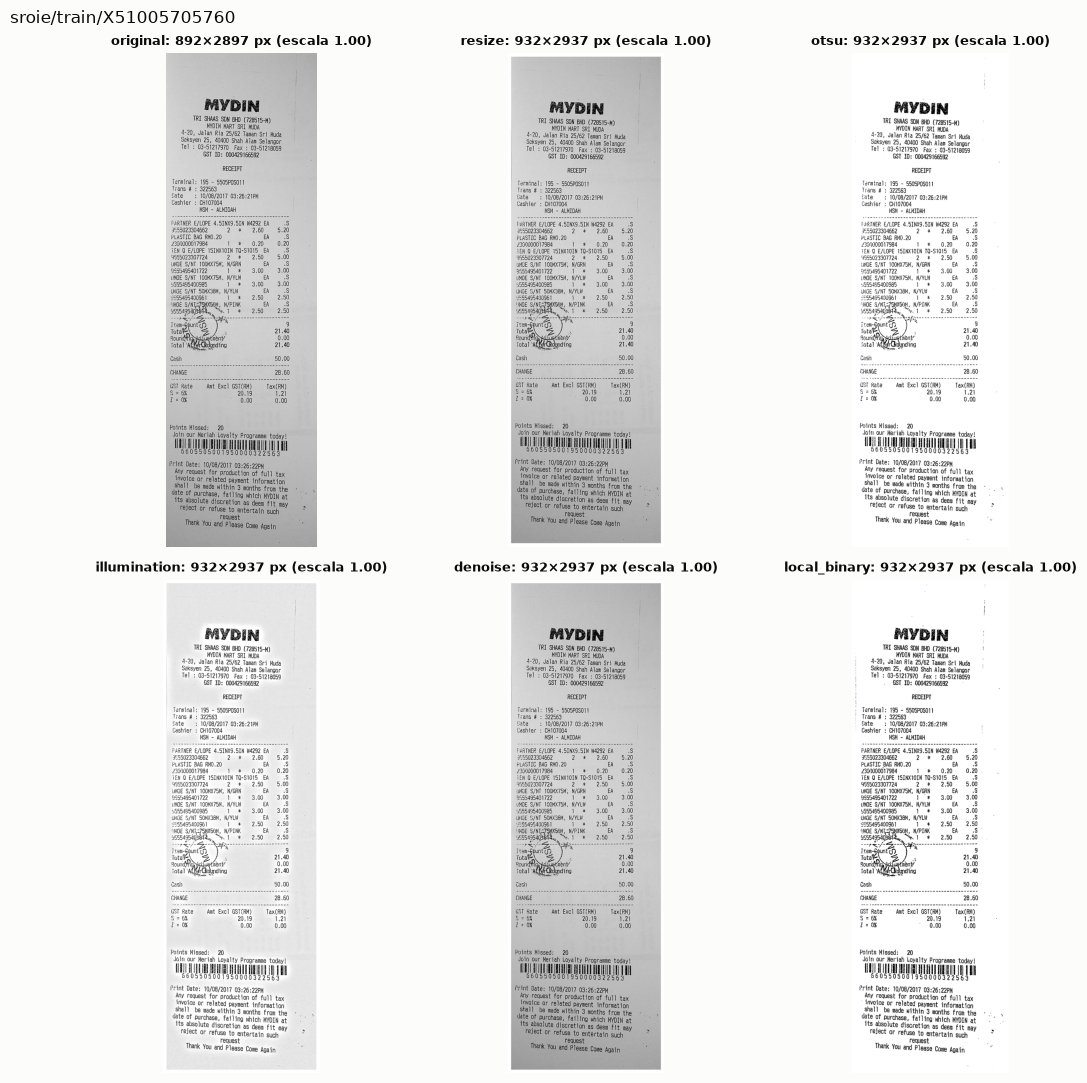

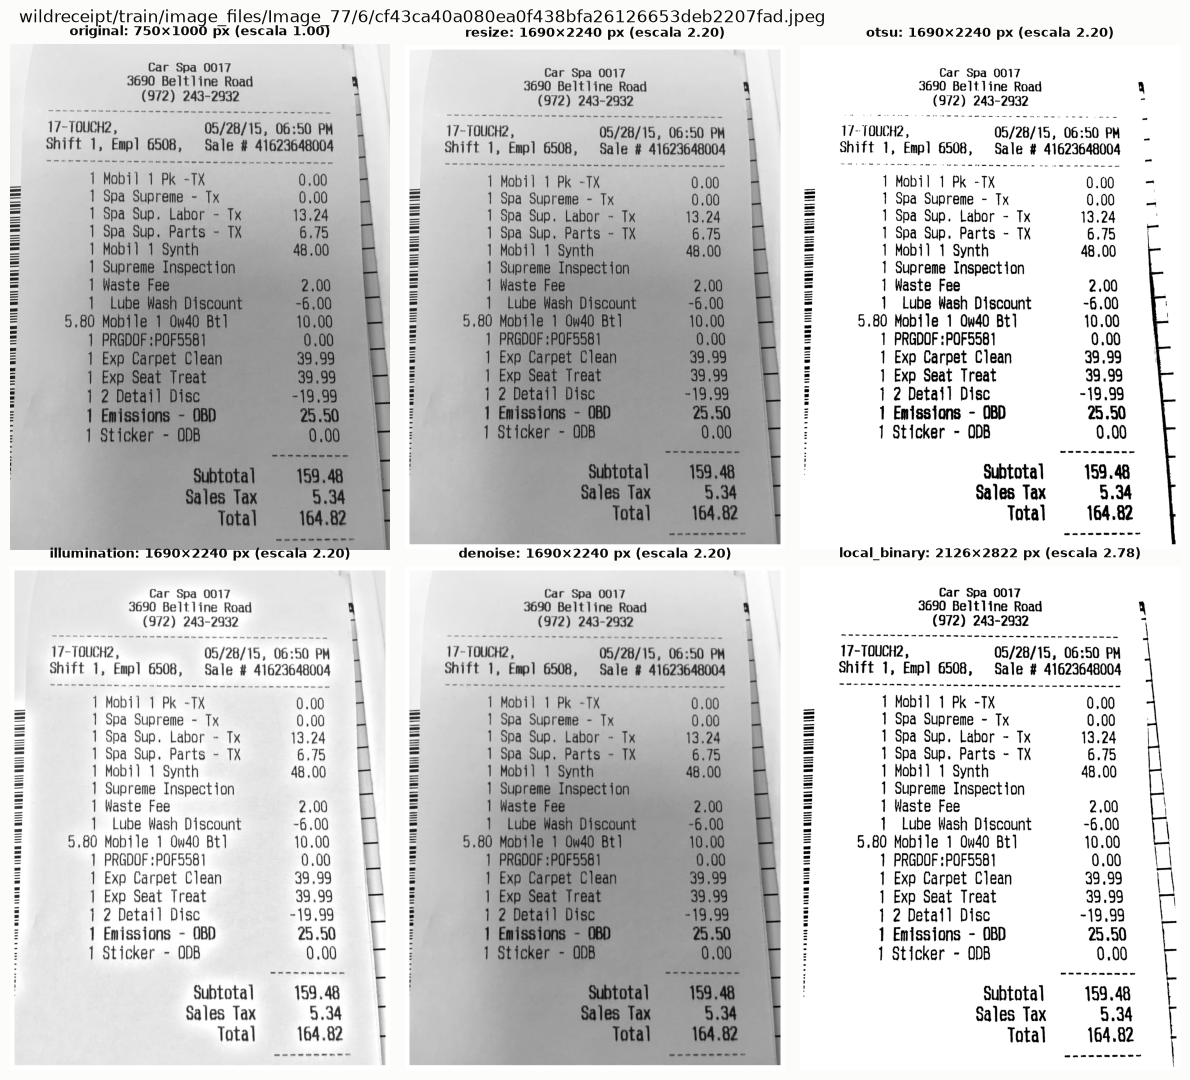

In [9]:
muestra, _ = validation_samples(FILAS, N_POR_BASE, 1, SEED)   # mismos primeros documentos que 03 y 04: reutiliza la caché
print('Documentos de validación para medir el OCR:', Counter(r['dataset'] for r in muestra))
ejemplos_img = [next(r for r in muestra if r['dataset'] == b) for b in ('sroie', 'wildreceipt') if any(r['dataset'] == b for r in muestra)]
RESCATE = {k: v for k, v in ocr['rescue_views'][0].items() if k in ('target_long_edge', 'max_scale', 'max_pixels', 'local_window', 'local_k')}
METODOS = [('original', {}), ('resize', {}), ('otsu', {}), ('illumination', {}), ('denoise', {}), ('local_binary', RESCATE)]
for fila in ejemplos_img:
    with Image.open(fila['image']) as im:
        im.load()
        fig, ejes = plt.subplots(2, 3, figsize=(12, 11))
        for ax, (metodo, extra) in zip(ejes.flat, METODOS):
            salida, t = prepare_image(im, dict(ocr, **extra, preprocess=metodo))
            ax.imshow(salida, cmap='gray'); ax.axis('off')
            ax.set_title(f"{metodo}: {salida.size[0]}×{salida.size[1]} px (escala {t['scale_x']:.2f})", fontsize=9)
        fig.suptitle(fila['id'], x=.02, ha='left'); plt.tight_layout(); plt.show()

### 4.2 Las coordenadas vuelven al tamaño original
Cada transformación guarda escala y borde. Comprobamos que una caja ida y vuelta queda en el mismo lugar (error < 1 px).

In [10]:
fila = ejemplos_img[0]
with Image.open(fila['image']) as im:
    _, t = prepare_image(im, dict(ocr, preprocess='resize'))
errores = []
for region in fila['regions'][:50]:
    x1, y1, x2, y2 = region['box']
    transformada = [x1 * t['scale_x'] + t['border'], y1 * t['scale_y'] + t['border'], x2 * t['scale_x'] + t['border'], y2 * t['scale_y'] + t['border']]
    errores.append(max(abs(a - b) for a, b in zip(original_box(transformada, t), region['box'])))
print(f'Error máximo de ida y vuelta: {max(errores):.6f} px en {len(errores)} cajas')
assert max(errores) < 1

Error máximo de ida y vuelta: 0.000000 px en 50 cajas


## 5. Efecto de cada vista en el OCR
Para cada documento de la muestra se ejecutan las 10 vistas (y las de rescate cuando se activan). Medimos:
- **CER** de cada vista contra la transcripción anotada (más bajo = mejor). Es sensible al orden de lectura, así que sirve para comparar vistas entre sí, no como benchmark oficial.
- **Palabras leídas** y **tiempo** por vista.
- **Valores de referencia encontrados**: si el valor normalizado de fecha/subtotal/impuesto/total aparece en el texto de la vista. Es una cota de lo que el extractor podría encontrar; muestra por qué combinar vistas ayuda.

La primera ejecución puede tardar 15–30 minutos en CPU; después se usa la caché (también la aprovechan 03 y 04).

In [11]:
from lector_facturas.candidate_rules import AMOUNT, DATE, MONTH_DATE

def valores_en_texto(texto):
    """Fechas y montos normalizados que aparecen en un texto OCR."""
    encontrados = set()
    for m in list(DATE.finditer(texto)) + list(MONTH_DATE.finditer(texto)):
        encontrados.add(('date', normalize('date', m.group(), CONFIG['normalization'])))
    for m in AMOUNT.finditer(texto):
        v = money(m.group(), CONFIG['normalization']['decimal_separator'])
        if v is not None:
            encontrados.add(('monto', v))
    return encontrados

registros, lecturas = [], {}
inicio = time.perf_counter()
for i, fila in enumerate(muestra, 1):
    try:
        resultado = transcribe(fila['image'], ocr, CACHE)
    except Exception as exc:
        print('Error en', fila['id'], exc); continue
    lecturas[fila['id']] = resultado
    referencia = cer_reference(fila)
    oro = {c: normalize(c, fila['gold'][c]['value'], CONFIG['normalization'])
           for c in ('date', 'subtotal', 'tax', 'total') if fila['gold'][c]['status'] == 'annotated'}
    for vista in resultado['views']:
        texto = vista['text']
        hallados = valores_en_texto(texto)
        registro = {'id': fila['id'], 'dataset': fila['dataset'], 'vista': nombre_vista(vista),
                    'palabras': len(vista['words']), 'segundos': vista['ocr_seconds'], 'cache': vista['cache_hit'],
                    'cer': edit_distance(cer_text(referencia), cer_text(texto)) / len(cer_text(referencia)) if referencia else np.nan}
        for c, v in oro.items():
            registro[f'hallado_{c}'] = (('date' if c == 'date' else 'monto'), v) in hallados
        registros.append(registro)
    if i % 10 == 0 or i == len(muestra):
        print(f'{i}/{len(muestra)} documentos · {time.perf_counter() - inicio:.0f} s')
vistas = pd.DataFrame(registros)
vistas.to_csv(SALIDAS / 'ocr_por_vista_validacion.csv', index=False, encoding='utf-8-sig')
print('Documentos con vistas de rescate:', vistas[vistas.vista.str.endswith('rescate')].id.nunique(), 'de', vistas.id.nunique())

10/30 documentos · 63 s


20/30 documentos · 110 s


30/30 documentos · 145 s
Documentos con vistas de rescate: 15 de 30


cer_mediano  cer_medio  palabras  segundos
dataset     vista                                                                      
sroie       denoise·psm6·esp                       0.193      0.200     145.0     0.694
            illumination·psm6·best                 0.172      0.189     145.0     0.853
            local_binary·psm11·best·rescate        0.630      0.745     174.0     1.482
            original·psm6·best                     0.180      0.181     144.0     0.819
            original·psm6·fast                     0.165      0.187     146.0     0.392
            otsu·psm6·fast                         0.195      0.212     147.0     0.393
            resize·psm11·best                      0.280      0.282     155.0     1.170
            resize·psm11·fast                      0.306      0.322     158.0     0.617
            resize·psm3·fast                       0.203      0.190     132.0     0.500
            resize·psm6·best                       0.187      0.181     145.0     0.838
            resize·psm6·best·rescate               0.534      0.531      98.0     1.040
            resize·psm6·fast                       0.193      0.184     147.0     0.467
wildreceipt denoise·psm6·esp                       0.722      0.670      84.0     0.603
            illumination·psm6·best                 0.507      0.578      99.0     0.604
            local_binary·psm11·best·rescate        0.800      0.744      61.0     0.649
            local_binary·psm6·best·rescate         0.669      0.669      88.0     0.724
            original·psm6·best                     0.517      0.493      74.0     0.312
            original·psm6·fast                     0.508      0.489      75.0     0.188
            otsu·psm6·fast                         0.563      0.611      87.0     0.324
            resize·psm11·best                      0.523      0.582      85.0     0.703
            resize·psm11·fast                      0.583      0.618      96.0     0.404
            resize·psm3·fast                       0.568      0.523      70.0     0.393
            resize·psm6·best                       0.512      0.543      85.0     0.604
            resize·psm6·best·rescate               0.729      0.712      32.0     0.413
            resize·psm6·fast                       0.536      0.578      86.0     0.399

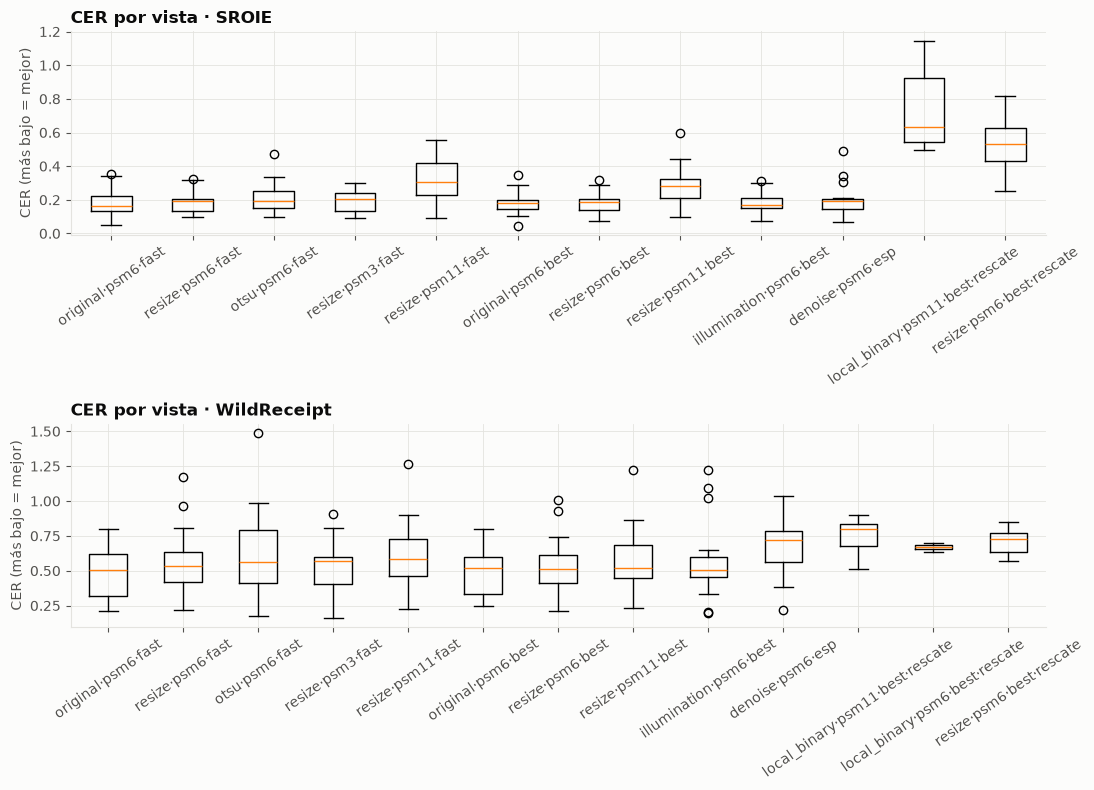

In [12]:
orden_vistas = ORDEN_VISTAS + sorted(set(vistas.vista) - set(ORDEN_VISTAS))
tabla_cer = vistas.groupby(['dataset', 'vista']).agg(cer_mediano=('cer', 'median'), cer_medio=('cer', 'mean'),
            palabras=('palabras', 'median'), segundos=('segundos', 'median')).round(3)
display(tabla_cer)
fig, ejes = plt.subplots(vistas.dataset.nunique(), 1, figsize=(11, 4 * vistas.dataset.nunique()), squeeze=False)
for ax, (base, g) in zip(ejes[:, 0], vistas.groupby('dataset')):
    presentes = [v for v in orden_vistas if v in set(g.vista)]
    ax.boxplot([g[g.vista == v].cer.dropna() for v in presentes])
    ax.set_xticks(range(1, len(presentes) + 1), presentes)
    ax.set_title(f'CER por vista · {F.NOMBRE[base]}', loc='left'); ax.set_ylabel('CER (más bajo = mejor)')
    ax.tick_params(axis='x', rotation=35)
plt.tight_layout(); fig.savefig(FIG / 'cer_por_vista.png', dpi=150); plt.show()

In [13]:
# ¿Cuántos valores de referencia aparecen en la vista principal, en las 5 vistas del modelo anterior y en todas las vistas?
columnas = [c for c in vistas.columns if c.startswith('hallado_')]
VISTAS_V7 = ['original·psm6·fast', 'resize·psm6·fast', 'otsu·psm6·fast', 'resize·psm3·fast', 'resize·psm11·fast']
filas_union = []
for (doc, base), g in vistas.groupby(['id', 'dataset']):
    for c in columnas:
        if g[c].notna().any():
            filas_union.append({'dataset': base, 'campo': c.replace('hallado_', ''),
                                'vista principal': bool(g[g.vista == PRINCIPAL][c].fillna(False).any()),
                                '5 vistas fast (V7)': bool(g[g.vista.isin(VISTAS_V7)][c].fillna(False).any()),
                                'todas las vistas (final)': bool(g[c].fillna(False).any())})
union = pd.DataFrame(filas_union)
tabla_union = union.groupby(['dataset', 'campo'])[['vista principal', '5 vistas fast (V7)', 'todas las vistas (final)']].mean().mul(100).round(1)
tabla_union['soporte'] = union.groupby(['dataset', 'campo']).size()
display(tabla_union)
print('Lectura: porcentaje de valores de referencia que aparecen escritos tal cual (normalizados) en el texto OCR.')

vista principal  5 vistas fast (V7)  todas las vistas (final)  soporte
dataset     campo                                                                           
sroie       date                 73.3               100.0                     100.0       15
            total                86.7                93.3                      93.3       15
wildreceipt date                 61.5                69.2                      84.6       13
            subtotal             81.8                90.9                     100.0       11
            tax                  72.7                72.7                      90.9       11
            total                75.0                91.7                      91.7       12

Lectura: porcentaje de valores de referencia que aparecen escritos tal cual (normalizados) en el texto OCR.


### 5.1 Figura 6 de la documentación: CER frente al tamaño de la imagen
Usamos la vista principal (ampliada · PSM 6 · pesos fast), que es la que el sistema reporta como texto del documento.

  figura: 06_cer_vs_resolucion.png


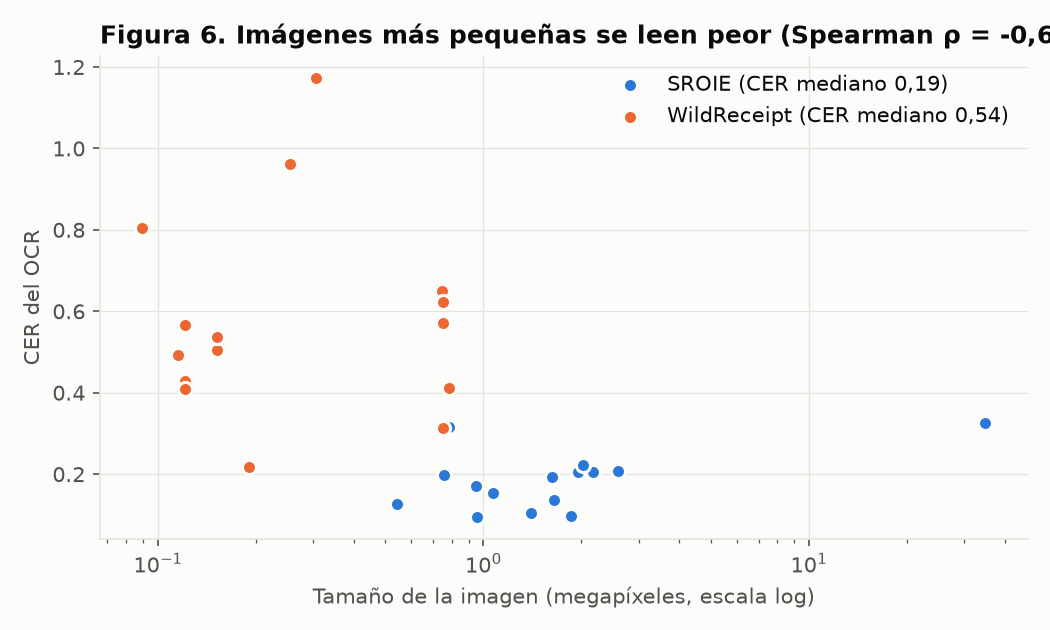

In [14]:
principal = vistas[vistas.vista == PRINCIPAL][['id', 'dataset', 'cer']].dropna()
documentos = pd.DataFrame([{'id': r['id'], 'dataset': r['dataset'], 'width': r['width'], 'height': r['height'],
                            'regions': len(r['regions'])} for r in muestra])
datos_cer = F.fig_cer(principal, documentos, FIG)
if datos_cer is not None:
    display(Img(filename=str(FIG / '06_cer_vs_resolucion.png')))

## 6. Entrada en PDF
Los PDF se convierten a una imagen por página a 200 dpi (máximo 20 páginas) y cada página se procesa por separado.

page_001.png (1134, 907)


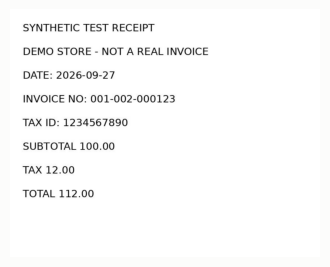

In [15]:
paginas = render_pdf(RAIZ / 'samples/synthetic_receipt.pdf', SALIDAS / 'pdf_demo')
for p in paginas:
    with Image.open(p) as im:
        print(p.name, im.size)
        plt.figure(figsize=(4, 6)); plt.imshow(im); plt.axis('off'); plt.show()

## 7. Salidas
- `outputs/.../notebooks/preparados/manifest.jsonl`: manifiesto con particiones y referencias (no se sube a Git).
- `outputs/.../notebooks/cache_ocr/`: lecturas OCR en caché; los notebooks 03 y 04 las reutilizan.
- `outputs/.../notebooks/ocr_por_vista_validacion.csv`: CER, palabras, tiempo y valores encontrados por vista.
- `figuras/cer_por_vista.png` y `figuras/06_cer_vs_resolucion.png`: CER por vista y frente al tamaño de la imagen (la versión del repositorio está en `results/figures/preprocesamiento/`).

**Conclusión:** cada vista se equivoca en lugares distintos. La tabla de la sección 5 compara cuántos valores de referencia aparecen en la vista principal, en las 5 vistas del modelo anterior y en todas las vistas del modelo final; esa diferencia es el margen que el consenso del notebook 03 intenta aprovechar, a cambio de más tiempo de OCR.